# Braintrak Python Implementation

In [1]:
from numpy import zeros
from matplotlib import pyplot as plt

import numpy as np

from scipy.io import loadmat

In [2]:
pars = np.array([1,1,1,1,1,1,1,1])

M = loadmat('/nethome/kcni/jgriffiths/Code/libraries_of_mine/github/shreytrak/code/braintrak/demo.mat')
demo_f = M['f']
demo_P = M['s_single']


f = '/nethome/kcni/jgriffiths/Code/libraries_of_mine/github/shreytrak/code/braintrak/+db_fit/pp_allstates.mat'

db_data = loadmat(f,struct_as_record=False,squeeze_me=True)['db_data']

force_wake_state = 1
filt = db_data.iswake == force_wake_state;
db_data.P = db_data.P[filt,:];
db_data.iswake = db_data.iswake[filt];
db_data.xyz = db_data.xyz[filt,:];
db_data.nus = db_data.nus[filt,:];
db_data.gab = db_data.gab[filt,:];


In [85]:
class model_template:
    
    electrodes = None
    
    
    """
    
    % These properties are SetAccess protected to ensure that the MCMC functions
    % are properly independent of the choice of model
    properties(SetAccess = protected) % Public access, but can only be edited via the interface
        name
        n_params
        param_names
        param_symbols
        param_units

        n_fitted % Expect to change during fitting. Number of parameters being fitted. this could be different if skip_fit changes
        initial_step_size % Standard deviations for initial chain (before adaptive covariance matrix is calculated)
        limits % Upper and lower bounds on parameter values
        skip_fit % Expect to change during fitting. 1 means distribution is fixed, 2 means parameter AND distribution are fixed
        electrodes % So that the model can choose its behaviour based on the electrodes

        target_f % Frequencies present in the data 
        target_P % Experimental power spectrum
        weights
        prior_pp % Shape of the prior distribution (a struct array, one for each parameter)
        prior_size = 50; % Number of points in the prior
    end

   	methods(Abstract)
        p_from_params(self,params) % Map parameters to point
        params_from_p(self,p) % Map point to parameters
        objective(self,pars) % Calculate the objective and the spectrum. Note that this syntax forces prepare_for_fit to be run
        initialize_fit(self,target_f,target_P) % Return the first posterior/prior and initial values
        get_xyz(self,params) % Turn whatever model parameters are specified into XYZ - params is a matrix
    end


    methods
    """
    
    def spectrum(self,pars,target_f):

        #if nargin < 3
        #    target_f = linspace(1,45,100);
        #end
        self.target_f = target_f;
        self.target_P = np.ones(size(self.target_f))/(target_f[1]-target_f[0]);
        self.set_cache(pars);
        chisq,P = self.objective(pars);
        stab = isfinite(chisq);
        P = P/utils_mex_trapz(target_f,P);
            
        
        return target_f,P,stab,chisq


    def default_t0_skip_fit(self,target_f,target_P,t0_index):
        #% Default skip fit behaviour for t0
        #% Replace this function internally if different behaviour is required


        self.skip_fit = zeros([1,self.n_params]);
        assert(isvector(target_P)); # % This function should not be used with multiple electrodes
        temp_analysis = model.get_spec_analysis(target_f,target_P);
        if temp_analysis.alpha_str < 5: #% Only fit t0 if alpha peak is present
            self.skip_fit[t0_index] = 1 #; % Change this to false to enable fitting t0 at all times
        else:
            self.skip_fit[t0_index] = 0;


        
    def prepare_for_fit(self,target_f,target_P,initial_values,prior_pp,skip_fit=None):
        
        if skip_fit is not None:
            self.skip_fit = skip_fit
            
        #self.n_fitted = sum(not self.skip_fit);
        self.n_fitted = sum(self.skip_fit == 0)
        self.target_f = target_f;
        self.target_P = target_P;
        self.prior_pp = prior_pp;
        self.set_cache(initial_values);

        
    def validate(self):
        #% This function is the first thing called by chain()
        #% and provides a last opportunity to detect any problems with the
        #% internal state of the model before model.probability is called
        #% Perform any checks/assertions required immediately before fitting
        if any(self.target_f==0):
            error('Weighting will only work with nonzero frequencies');

    def get_weights(self,target_f): # % Default weighting function
        w = np.ones(len(target_f));
        w = target_f**(-1); # % Decades equally weighted
        w[target_f < 1] = 0; # % Ignore frequencies below 1Hz 
        #w = w(:);
        
        return w
        
        
    def set_electrodes(self,data):
        """
        if isstruct(data):
            self.electrodes = data.colheaders;
        elif iscell(data):
            self.electrodes = data;
        else:
            self.electrodes = {data};
        """
        self.electrodes = data

    def uniform_priors(self):
        prior_pp = make_prior_pps()
        nj = len(self.limits)
        prior_pp.x = np.zeros([self.prior_size,nj])
        prior_pp.y = np.zeros([self.prior_size,nj])       
        prior_pp.ndx = np.zeros(nj)
        for j in np.arange(0,nj):#  1:len(self.limits): # size(self.limits,2)
            a=np.linspace(self.limits[0,j],self.limits[1,j],self.prior_size);
            #b=np.ones([self.prior_size,1]);
            b=np.ones(self.prior_size);
            prior_pp.x[:,j] = a;
            prior_pp.y[:,j] = b;
            prior_pp.ndx[j] = 1/(a[1]-a[0]);
        return prior_pp

    
    #% This is called by probability
    #% Overload this to perform more sophisticated checks
    def validate_params(self,pars):
        valid = !any(pars >= self.limits[1,:] | pars <= self.limits[0,:]);
        return valid
    #end


    def probability(self,pars):
        P = [];
        chisq = NaN;
        likelihood = NaN;
        prob = NaN;

        # % Use the base class to validate params
        # % this will occur before any adapter code
        if not self.validate_params(pars):
            return

        [chisq,P] = self.objective(pars);
        if isfinite(chisq):
            likelihood = exp(-chisq/2);
            prob = likelihood*self.eval_priors(pars);
        else:
            likelihood = 0;
            prob = 0;
        return chisq,prob,likelihood,P
    

    def eval_priors(self,xi):
        # % Evaluates all priors and returns the product of them
        # % Note that the proposed values must have been checked to lie within the allowed limits
        # % BEFORE this function is called
        xi = xi - self.prior_pp.x[1,:] #% The difference between the trial parameter and the first x value
        fxi = floor(xi*self.prior_pp.ndx)+1;# % The index in which the value is found
        Yi = (fxi-xi*self.prior_pp.ndx)*diag(self.prior_pp.y[fxi,:]).T+(1-fxi+xi*self.prior_pp.ndx)*diag(self.prior_pp.y[fxi+1,:]).T;
        p = prod[Yi];
        return p
    

    def make_posterior(self,out,lim):
        # % Given the output run (npts x 8 params)
        # % Return the posterior distribution in pp format
        #if nargin < 3 || isempty(lim):
        #    lim = self.limits;

            
        for j in np.arange(0, len(lim)): # ,2)):
            x_final = linspace(lim[0,j],lim[1,j],self.prior_size); # % The final bin edges
            x_center = x_final[1:]-(x_final[1]-x_final[0])/2;
            y_center = hist(out[:,j],x_center);
            y_final = interp1(x_center,y_center,x_final,'linear','extrap');
            y_final[y_final < 0] = 0;
            posterior_pp.x[:,j] = x_final;
            posterior_pp.y[:,j] = y_final/trapz(x_final,y_final);
            posterior_pp.ndx[j] = 1/(x_final[1]-x_final[0]);
            
        return posterior_pp 

    
    def xyz_posterior(self,out):
        xyz_vals = self.get_xyz(out);
        xyz_lim = np.array([[0,  -1  ,   0 ], [1 ,  1 ,  1.3]]);
        post = self.make_posterior(xyz_vals,xyz_lim);
        return post
        

    def xyz_present(self):
        # % Returns [true true true] if there is a parameter
        # % with name 'X','Y', or 'Z' respectively
        # % e.g. [1 1 1] for reduced model, [0 1 1] for reduced_l
        # % and [0 0 0] for full model\
        # present = [any(strcmp(self.param_names,'X')) any(strcmp(self.param_names,'Y')) any(strcmp(self.param_names,'Z'))];
        
        
        
        return present
    

    

class model_params(object):
    def __init__(self):
        self.gabcd = None
        self.alpha = None
        self.beta = None
        self.t0 = None
        self.emg_a = None

        
        

class model_full(model_template):
    

    # % This model is set up to fit t0 keeping the prior fixed if the alpha peak is not present
    # % Note that prepare_for_fit must be used before spectrum() can be used
    # % Uniform priors and DB initial fit


    def __init__(self):
        
        self.kmax = None
        self.k0 = None
        self.k2u = None
        self.k2_volconduct = None

        self.stab_gamma_prefactor = None
        self.spec_gamma_prefactor = None

        self.stab_w = None
        self.spec_w = None

        #self.p = None
        self.emg = None
        self.normalization_target = None
        self.stab_Mtot = None
        self.spec_Mtot = None
        self.compute_Mtot = None

        
        
        
        
        
        self.name = 'model_full';
        self.n_params = 9;
        self.param_names = ['Gee','Gei','Gese','Gesre','Gsrs','Alpha','Beta','t0','EMGa']
        self.param_symbols = ['G_{ee}','G_{ei}','G_{ese}','G_{esre}','G_{srs}','\alpha','\beta','t_0','A_{EMG}']
        self.param_units = ['','','','','','s^{-1}','s^{-1}','ms','']

        self.n_fitted = 9;
        self.skip_fit = zeros([1,self.n_fitted]);


        self.initial_step_size = [0.4 , 0.4 ,  1 , 1 , 0.2 , 5 , 40 , 0.005 , 0.05];
        self.limits = np.array([[ 0 , -40  ,   0   ,  -40   ,   -5    ,  10   ,   100  ,  0.075 ,  0    ],
                       [ 20 ,   0  ,     40 ,      0 ,      0  ,    100 ,   800 ,   0.14 ,  1  ]])

        self.kmax = 4;
        self.k0 = 10; #% Volume conduction parameter
        self.p = model_params() #  model.params;
        self.p.phin = 1e-5;
        
        #% Limits based on stability_3d
        #% Somewhat tighter ranges
        #% EMG ranges based on spectfit output generated by sacha, speciically spec10000113.fit

        self.prior_size = 50

        

    def p_from_params(self,fitted_params): # % Map parameters to point
        p = model_params() #p = model.params;
        p.gabcd = fitted_params[:4];
        #p.alpha(:) = fitted_params[6];
        p.alpha = fitted_params[5];
        #p.beta(:) = fitted_params[7];
        p.beta = fitted_params[6];
        p.t0 = fitted_params[7];
        p.taues = p.t0/2;
        p.tause = p.t0/2;
        p.emg_a = fitted_params[8];
        return p

    def params_from_p(self,p): # % Map point to parameters
        params = [p.gabcd, p.alpha[0], p.beta[0], p.t0, p.emg_a];

    def validate_params(self,pars):
        #valid = ~(pars(1)/pars(2) > -0.5 || (pars[1] + pars[2]) > 1 || pars[7]/pars[6] > 20 || any(pars >= self.limits[2,:] | pars <= self.limits[1,:] ));
        test1 = test2 = test3 = test4 = False
        
        test1 = pars[0]/pars[1] > -0.5
        test2 = pars[0]+pars[1] > 1 
        test3 = pars[6]/pars[5] > 20 
        test4 = ((pars >= self.limits[1,:]) or (pars <= self.limits[0,:]))
        valid_test = not (test1 or test2 or test3 or test4)
        return valid_test 

        
    def objective(self,pars): # % Calculate the objective
        P = [];
        chisq = np.nan # NaN;

        if self.compute_Mtot: # % If this flag has been set to false, then these fields are already present
            #% Should be fine to let that just throw an undefined variable error later if this isn't the case
            self.stab_Mtot = exp(1j*self.stab_w*pars[7]);
            self.spec_Mtot = exp(1j*self.spec_w*pars[7]);

        stab_L = 1./((1-1j*self.stab_w/pars[5])*(1-1j*self.stab_w/pars[6]));
        spec_L = 1./((1-1j*self.spec_w/pars[5])*(1-1j*self.spec_w/pars[6]));

        stab_gamma_prefactor = self.stab_gamma_prefactor;
        d=(stab_gamma_prefactor*(1-stab_L*pars[1])-stab_L*pars[0])*(1-stab_L*stab_L*pars[4])-stab_L*stab_L*self.stab_Mtot*(pars[2]+stab_L*pars[3]);      

        stab1=d[0]>0 
        stab2 = not ( any(real(d[1:end])<0 & imag(d[1:end])*imag(d[0:-1])<0) );
        stab = stab1 & stab2

        if not stab:
            return
  
        # % And the spectrum
        Jei_oneminus = 1-spec_L*pars[1];
        Jsrs_oneminus = 1-spec_L*spec_L*pars[4];

        re2 = self.p.re**2

        q2re2 = (self.spec_gamma_prefactor - 1./(Jei_oneminus)*(spec_L*pars[0] + ((spec_L*spec_L*pars[2] + spec_L*spec_L*spec_L*pars[3])*self.spec_Mtot)/(Jsrs_oneminus)));
        T_prefactor = spec_L*spec_L*self.p.phin/(Jei_oneminus*Jsrs_oneminus);
        # % T prefactor doesn't have a exp(i*omega*t0/2) term because the modulus of this is 1
        P = zeros(size(self.spec_w));

        k2u = self.k2u;
        k2_volconduct = self.k2_volconduct;

        for j in range(0,len(k2u)):#= 1:size(k2u,1)
            P = P + k2u[j,1]*abs(T_prefactor/(k2u[j,0]*re2+q2re2))**2 * k2_volconduct[j]; # % For use with the efficient way
  
        P = P + 1e-12*pars[8]*self.emg; # % Add the EMG component
    
        P = P/utils.mex_trapz(self.target_f(self.weights>0),P(self.weights>0));
        P = self.normalization_target*P;
        sqdiff = (abs(P-self.target_P)/self.target_P)**2 # ; % This is the squared fractional difference
        chisq = sum(sqdiff*self.weights);

        
        return chisq,P
        
        
    def initialize_fit(self,target_f,target_P,eps=2.2204e-16): # % Return the first posterior/prior and initial values
        #f1,P1,idx,db_data = db_fit.quick_fit(self,target_f,target_P);
        f_fitted,P_fitted,idx,db_data,min_chisq = quick_fit(self,target_f,target_P);
        f1,P1,idx,db_data = f_fitted,P_fitted,idx,db_data
        
        #%loglog(target_f,target_P,f1,P1)
        a =  db_data.gab[idx,:];
        p = model_params(db_data.iswake[idx]);

        initial_values =  [a[0], a[1], a[2]*a[3], a[2]*a[4]*a[6], a[4]*a[7], p.alpha[0], p.beta[0], p.t0, eps];

        prior_pp = self.uniform_priors();
            
        return initial_values,prior_pp           
        
        
    def set_cache(self,initial_values): # % Calculate the cache - takes in skip_fit

        # % Cache for the mcmc fit code
        # % Lower resolution, dynamic alpha and beta
        Lx = 0.5; # % linear dimensions of cortex (assume square)
        dk = 2*pi/Lx;
        m_rows = np.arange(-self.kmax,self.kmax) #-self.kmax:self.kmax; 
        n_cols = np.arange(-self.kmax,self.kmax) #-self.kmax:self.kmax; 
        kxa,kya = meshgrid(dk*m_rows,dk*n_cols); 
        k2 = kxa**2+kya**2;
        k2u = unique(k2);
        #self.k2u = [k2u, histc(k2,k2u)]; # % First col is the k2 value, second is how many times it appeared
        self.k2u = [k2u, np.histogram(k2,bins=k2u)]; # % First col is the k2 value, second is how many times it appeared
        self.stab_w=2*pi*np.linspace(0,100,5000); # % High res array, 0 to 100Hz with 10000 points
        self.spec_w = self.target_f*2*pi;

        self.stab_w = self.stab_w#(:);
        self.spec_w = self.spec_w#(:);

        self.stab_gamma_prefactor = (1-1j*self.stab_w/self.p.gammae)**2;
        self.spec_gamma_prefactor = (1-1j*self.spec_w/self.p.gammae)**2;

        self.weights = self.get_weights(self.target_f);

        #self.k2_volconduct = exp(-k2u[:,0]/self.k0**2);
        self.k2_volconduct = exp(-k2u/self.k0**2);

        emg_f = 40;
        self.emg = (self.spec_w/(2*pi*emg_f))**2/(1+(self.spec_w/(2*pi*emg_f))**2)**2;

        if ~isempty(self.target_P):
            # % If this cache file is being generated for a specific fit instance
            self.normalization_target = utils.mex_trapz(self.target_f(self.weights>0),self.target_P(self.weights>0));


        if (self.skip_fit[8] == 2 ) and (not (initial_values == None)): #  && ~isempty(initial_values) # % If t0 is not being fitted, then the value is of course fixed
            self.stab_Mtot = exp(1j*self.stab_w*initial_values[7]);
            self.spec_Mtot = exp(1j*self.spec_w*initial_values[7]);
            self.compute_Mtot = False;
        else:
            self.compute_Mtot = True; 
        
    def get_xyz(self,params): # % Turn whatever model parameters are specified into XYZ - params is a matrix
        xyz[:,0] = params[:,0]/(1-params[:,1]);
        xyz[:,1] = (params[:,2]+params[:,3])/(1-params[:,4])/(1-params[:,1]);
        xyz[:,2] = -params[:,4]*params[:,5]*params[:,6]/((params[:,5]+params[:,6])**2);

        return xyz
        
        
        
    """
    def prepare_for_fit(self,varargin):
        
        
        # % argument list: target_f,target_P,initial_values,prior_pp,skip_fit
        if nargin < 6 || isempty(varargin{5}):
            self.default_t0_skip_fit(varargin{1},varargin{2},8);
        else:
            assert(length(varargin{5}) == self.n_params);
            self.skip_fit = varargin{5};
        #end

        prepare_for_fit@bt.model.template(self,varargin{1:4});
            
        # TO DO: simpler version of whatever it is this is doin
        
        thing = None
    """
    
    def prepare_for_fit(self,target_f,target_P,initial_values,prior_pp,skip_fit=None):
        #self.n_fitted = sum(not self.skip_fit);
        self.n_fitted = sum(self.skip_fit == 0)        
        self.target_f = target_f;
        self.target_P = target_P;
        self.prior_pp = prior_pp;
        self.set_cache(initial_values);
        
        
        
        
        

def quick_fit(model,target_f,target_P,force_wake_state=1):
    """
    % Fit a power spectrum to a parameter combination already in a database
    % Arguments are
    % model - BrainTrak model
    % target_f - experimental frequencies
    % target_P - experimental power
    % force_wake_state - set to 1 for wake and 0 for sleep, to fit to only these states. Leave empty otherwise
    """
    #import utils.mex_trapz
    
    
    target_f = np.squeeze(target_f)
    target_P = np.squeeze(target_P)
    
    f = '/nethome/kcni/jgriffiths/Code/libraries_of_mine/github/shreytrak/code/braintrak/+db_fit/pp_allstates.mat'
    db_data = loadmat(f,struct_as_record=False,squeeze_me=True)['db_data']
    #pp_allstates
    
    #load db_fit/pp_allstates

    if force_wake_state: 
        filt = db_data.iswake == force_wake_state;
        db_data.P = db_data.P[filt,:];
        db_data.iswake = db_data.iswake[filt];
        db_data.xyz = db_data.xyz[filt,:];
        db_data.nus = db_data.nus[filt,:];
        db_data.gab = db_data.gab[filt,:];
    
    
    #target_P = (np.interp(target_f,target_P,db_data.f,'linear','extrap'));
    target_P = np.interp(db_data.f,target_f,target_P)#ta.f,'linear','extrap'));
    weights = model.get_weights(db_data.f);
    #normalization_target = mex_trapz(db_data.f(weights>0),target_P(weights>0));   
    normalization_target = np.trapz(db_data.f[weights>0],target_P[weights>0]);   

        
    chisq = np.zeros([len(db_data.P)]);
    norm_pp = db_data.P;
    for j in range(0, len(db_data.P)): #  1:size(db_data.P,1)
        #norm_pp[j,:] = normalization_target*norm_pp[j,:]/mex_trapz(db_data.f(weights>0),norm_pp(j,weights>0));
        norm_pp[j,:] = normalization_target*norm_pp[j,:]/np.trapz(db_data.f[weights>0],norm_pp[j,weights>0]);
        
        sqdiff = (abs(norm_pp[j,:]-target_P)/target_P)**2; # % This is the squared fractional difference
        chisq[j] = sum(sqdiff*weights);
    #end

    min_chisq = min(chisq); # % min chisq is the same as max likelihood with no/uniform priors
    idx = np.argmin(chisq)
    #idx = idx[1];

    P_fitted = norm_pp[idx,:];
    f_fitted = db_data.f;

    
    return f_fitted,P_fitted,idx,db_data,min_chisq



class make_prior_pps():
    
    x = None
    y = None
    ndx = None
    

class model_template(object):

    def initialize_fit(self,target_f,target_P):
    
        init_default = None
        prior_default = None
    
        return init_default,prior_default
      
    def set_electrodes(self,electrodes):
        return None

    
    def prepare_for_fit(self,target_f,target_P,initial_values,prior_pp,skip_fit):
        return None
    

    def probability(self,fitted_params):
        return fit_data.fitted_chisq,_,likelihood,fitted_P

    def make_posterior(out):
        return posterior_pp
        
    def xyz_posterior(out):
        return xyz_posterior
    
    def get_xyz(fitted_params):
        return xyz
    
    def p_from_params(fitted_params):
        return p
    
    

def bt_core_chain(model,initial_values,npoints,debugmode,timelimit):
    
    return out,posterior_out,accept_ratio


def utils_simple_bin3d(xyz,xyzlim,gridres):
    return Vcount

class tent(object):
    def compute(alpha,beta,t0,gammae):
        return tent_x,tent_y,tent_z,tent_u
    
    
    

def fit_spectrum(model,target_f,target_P,prior_pp=None,initial_values=None,
                 npoints=None,target_state=None,skip_fit=None,debugmode=None):
                 
    """
    % Take in a model, spectrum, prior distribution, initial values, and chain length
    % Return a feather object
    % The posterior distribution correctly reflects the skip_fit state of the model
    % This function is intended to be called via a wrapper like fit_single
       
    % Correctly set the skip_fit state of the model and normalization target
    % As a hacky workaround - can supply npoints as '15s' for a time limit
    """
                 
    #tic;

    #if nargin < 9 || isempty(debugmode)
    #    debugmode = false;
    #end

    #if nargin < 8 || isempty(skip_fit)
    #    skip_fit = [];
    #end

    #if nargin < 7 || isempty(target_state)
        #target_state = 'N/A';
    #end

    #if nargin < 6 || isempty(npoints)
        #npoints = '10s'; % Default run time
    #end

    #if ischar(npoints)
        #timelimit = sscanf(npoints,'%fs');
        #npoints = 1e5; % Default burning - this needs to be tuned
    #else
        #timelimit = false;
    #end
                 

    init_default,prior_default = model.initialize_fit(target_f,target_P)
    
    if initial_values == None:
        initial_values = init_default
        
    if prior_pp == None:
        prior_pp = prior_default
        
    #if (nargin < 5 || isempty(initial_values)) || (nargin < 4 || isempty(prior_pp))
        #[init_default,prior_default] = model.initialize_fit(target_f,target_P);
    #	if (nargin < 5 || isempty(initial_values)) 
            #initial_values = init_default;
        #end
    #	if (nargin < 4 || isempty(prior_pp))
            #prior_pp = prior_default;
        #end
    #end

    #if nargin < 3 || isempty(target_P) || isempty(target_f) || isempty(model)
        #error('You must provide a minimum of the model, target_f and target_P to use this function')
    #end

    #if isempty(model.electrodes)
        #model.set_electrodes('Cz');
    #end
    if model.electrodes == None:
        model.set_electrodes('Cz')

    #if size(target_P,2) ~=length(model.electrodes)
        #error('The number of electrodes in the model and the number of electrodes in the data are different. Did you run `model.set_electrodes()` correctly?')
    #end

    model.prepare_for_fit(target_f,target_P,initial_values,prior_pp,skip_fit)
    #model.prepare_for_fit(target_f,target_P,initial_values,prior_pp,skip_fit);

    #% Compute the chain
    #try
        #pool = gcp('nocreate');
    #catch
        #nworkers = matlabpool('size');
        #if nworkers == 0
            #pool = [];
        #else
        #	pool.NumWorkers = nworkers;
        #end
    #end

    #if isempty(pool)
        #fprintf('Single CPU mode\n');
        #[out,posterior_out,accept_ratio] = bt.core.chain(model,initial_values,npoints,debugmode,timelimit);
    #else
        #fprintf('Parallel mode with %d workers\n',pool.NumWorkers);
        #[out,posterior_out,accept_ratio] = bt.core.chain_parallel(model,initial_values,npoints,debugmode,timelimit);
    #end
    out,posterior_out,accept_ratio = bt_core_chain(model,initial_values,npoints,debugmode,timelimit);
    
    
    #% Pick and evaluate the fitted parameters
    fit_data.target_f = target_f;
    fit_data.target_P = target_P;
    fit_data.skip_fit = model.skip_fit;
    fit_data.chain_length = length(posterior_out);
    _,b = max(posterior_out);
    fit_data.fitted_params = out[b,:];
    fit_data.fitted_posterior = posterior_out(b);
    fit_data.posterior_pp = model.make_posterior(out);
    fit_data.xyz_posterior = model.xyz_posterior(out);
    
    fit_data.fitted_chisq,_,likelihood,fit_data.fitted_P = model.probability(fit_data.fitted_params);

    fit_data.bic = -2*log(likelihood)+model.n_fitted*log(sum(model.weights>0));
    fit_data.aic = 2*model.n_fitted - 2*log(likelihood);
    fit_data.aicc = fit_data.aic + (2*model.n_fitted*(model.n_fitted+1))/(sum(model.weights>0) - model.n_fitted - 1);
    
    fit_data.xyz = model.get_xyz(fit_data.fitted_params);
    fit_data.fit_time = toc;
    fit_data.state_str = target_state;


    #% If the model is calling for the posterior distribution to be held constant
    #% then copy the prior distribution into the posterior distribution 
    for j in range(0,len(fit_data.skip_fit)): #1:len(fit_data.skip_fit):
        if fit_data.skip_fit[j]:
            fit_data.posterior_pp.x[:,j] = prior_pp.x[:,j];
            fit_data.posterior_pp.y[:,j] = prior_pp.y[:,j];
            fit_data.posterior_pp.ndx[:,j] = prior_pp.ndx[:,j];
        #end
    #end
    
    #% Compute the Vcount matrix for plotting later
    plot_data.xyzlim = [[0,  -1,     0],[ 1,   1,   1.3]];
    plot_data.gridres = 0.025;
    xyz = model.get_xyz(out);
    plot_data.Vcount = utils.simple_bin3d(xyz,plot_data.xyzlim,plot_data.gridres);
    plot_data.accept_ratio = accept_ratio;

    p = model.p_from_params(fit_data.fitted_params);
    [plot_data.tent_x,plot_data.tent_y,plot_data.tent_z,plot_data.tent_u] = tent.compute(p.alpha(0),p.beta(0),p.t0,p.gammae);
    plot_data.tent_alpha = +(plot_data.tent_x+plot_data.tent_y<0.90 & plot_data.tent_x > 0 & plot_data.tent_x < 1);

    f_out = bt.feather(model,fit_data,plot_data);

    
    
    return f_out,fit_data,plot_data






class model_params:
    

    
    """
        properties
    """
    Lx          = 0.5;
    Ly          = 0.5;
    alpha       = [];
    beta        = [];
    t0          = 85e-3;
    taues       = 0.0425; # % t0/2
    tause       = 0.0425;
    qmax        = 340;
    gammae      = 116;
    re          = 86e-3
    gammas      = 1.2e4;
    rs          = 1.5e-3;#			% From page 78 of Thalamus I
    gamman      = 1.2e4;
    rn          = 2e-3; #			% From page 64 of 'Exploring the Thalamus', multiplied by 10 to get cortical map units 	
    sigma       = 3.8e-3; #			%	Threshold spread (V)
    theta       = 3.4*3.8e-3; #		%	Default is 3.4*sigma. Threshold ratio * sigma (Nondimensional)
    phin        = 1e-5; #				%	Stimulus effective firing rate (s^-1)


    nus         = [];
    gab         = [];
    gabcd       = [];
    xyz         = [];
    ve          = [];
    phia        = [];
    nroots      = 0;
    stab        = np.nan # NaN
    emg_a       = 0;
    emg_f       = 40; #  % Hz
    f           = np.linspace(0,45,1000);
    pe          = [];
    q2          = [];

    
    #% ranges for nus, gab and xyz
    #% size must be 2 x length(nus)
    #% range_xx(1, :) - lo
    #% range_xx(2, :) - hi
     
    range_nus = [];
    range_gab = [];
    
    #% size 2 x 3
    range_xyz = [];    
    spatial_t0  = 0;
    spatial_nus = [] # {};
    spatial_gab = [] # {};
    spatial_gabcd = [] # {};
    spatial_alpha = [] # {}; #% If there is only one element in this array, it is used for all of the L's
    spatial_beta = [] # {}; 
    
    
    spatial_xyz = []; # {}; #% Note that XYZ takes precedence if it is defined
    
    spatial_emg = []; # {}; #% Spatial EMG_a values

    
    #% Cell for labeling the params structure
     
    label = ['default'];

    
    disable_set = True # true; % This flag stops any additional code in the set functions from running
    
    """


    def __init__(self,alphamode=None):
        #% First argument is alphamode OR a point struct
        #% alphamode= 1 -> All wake
        #% alphamode= 0 -> All sleep

        #% Handle construction from a point struct
        #if nargin > 0 && isstruct(varargin{1})


    """


    """
    p = varargin{1};
    fieldname = fields(p);
    for j = 1:length(fieldname)
        switch fieldname{j} % Handle some mistakes made earlier with field names changing
    case 'ves'
        self.ve = p.ves;
    case 't0_amp'
        continue
    otherwise
        self.(fieldname{j})= p.(fieldname{j});
        self.complete_gab(1);
        self.disable_set= false;
        return

    if nargin < 1 or isempty(varargin{1})
        alphamode = 1; #% Wake by default
    else
        alphamode = varargin{1};                
    #    end
    """
    

    def __init__(self,alphamode=1):


        # % More alphamodes in Revision 785
        if alphamode == 1:
            av= 1/12e-3;  # %	1/Decay time (s^-1) WAKE
            bv= 1/1.3e-3; # %	1/Rise time (s^-1)  WAKE
        else:
            av= 45;
            bv= 185;

        self.alpha= np.ones([1,8])*av;
        self.beta= np.ones([1,8])*bv;
        self.disable_set= False
       
        """

        def set_nuz(self.val): # function set.nus(self,val)
            self.nus= val;

            if self.disable_set:
                return

            if ~isempty(val):
                if ~isempty(self.phia):
                    self.complete_gab(1);
                    else:
                        self.complete_gab();


        def set_gab(self,val)
            self.gab = val;

            if self.disable_set:
                return

            if ~isempty(val):
                if ~isempty(self.phia):
                    self.complete_nuab(0);
                    else:
                        self.complete_nuab();

        def keep_solution(self,n)
            #% Use complete_gab to keep only one of the solutions
            self.phia= self.phia(n,:);
            self.complete_gab(0);

        """;

In [77]:
thing = make_prior_pps()
thing.ndx

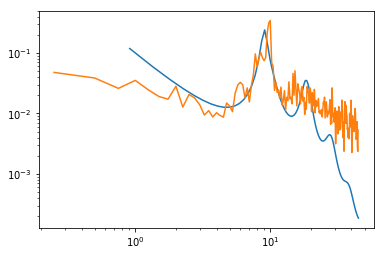

In [4]:
f_fitted,P_fitted,idx,db_data,min_chisq = quick_fit(model_full(),demo_f,demo_P)

fig, ax = plt.subplots()

ax.loglog(f_fitted,P_fitted)
ax.loglog(np.squeeze(demo_f),np.squeeze(demo_P.T));

In [80]:
from numpy import pi,exp

from numpy import meshgrid

from numpy import unique

In [86]:
mod = model_full()

ps = model_params()

demo_f_sq = np.squeeze(demo_f)
demo_P_sq = np.squeeze(demo_P)

#prior_pp = np.ones([1,8])
#prior_pp
prior_pp = model_params()

fit_spectrum(mod,demo_f_sq,demo_P_sq,prior_pp)

NameError: name 'isempty' is not defined

In [82]:
%debug

> <ipython-input-76-78389593fdfb>(400)set_cache()
    398         self.weights = self.get_weights(self.target_f);
    399 
--> 400         self.k2_volconduct = exp(-k2u[:,0]/self.k0**2);
    401 
    402         emg_f = 40;

ipdb> k2u.shape
(15,)
ipdb> self.k0.shape
*** AttributeError: 'int' object has no attribute 'shape'
ipdb> self.k0
10
ipdb> -k2u[:,0]/self.k0**2
*** IndexError: too many indices for array
ipdb> k2u[:,0] / 5
*** IndexError: too many indices for array
ipdb> k2u[:,0]
*** IndexError: too many indices for array
ipdb> k2u.shape
(15,)
ipdb> c


In [75]:
np.histogram(k2,bins=k2u)

In [ ]:
from numpy import hi

In [64]:
%debug

> <ipython-input-62-6328689037fa>(444)prepare_for_fit()
    442 
    443     def prepare_for_fit(self,target_f,target_P,initial_values,prior_pp,skip_fit=None):
--> 444         self.n_fitted = sum(not self.skip_fit);
    445         self.target_f = target_f;
    446         self.target_P = target_P;

ipdb> self.skip_fit
array([[0., 0., 0., 0., 0., 0., 0., 0., 0.]])
ipdb> not self.skip_fit
*** ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()
ipdb> ! self.skip_fit
*** IndentationError: unexpected indent
ipdb> ( ! self.skip_fit ) 
*** SyntaxError: invalid syntax
ipdb> self.skip_fit
array([[0., 0., 0., 0., 0., 0., 0., 0., 0.]])
ipdb> self.skip_fit == 0
array([[ True,  True,  True,  True,  True,  True,  True,  True,  True]])
ipdb> c


In [14]:
np.linspace(0,20,15)

array([ 0.        ,  1.42857143,  2.85714286,  4.28571429,  5.71428571,
        7.14285714,  8.57142857, 10.        , 11.42857143, 12.85714286,
       14.28571429, 15.71428571, 17.14285714, 18.57142857, 20.        ])

In [383]:
%debug

> <ipython-input-380-56155d31759b>(347)initialize_fit()
    345         #%loglog(target_f,target_P,f1,P1)
    346         a =  db_data.gab[idx,:];
--> 347         p = model.params(db_data.iswake[idx]);
    348 
    349         initial_values =  [a[1], a[2], a[3]*a[4], a[3]*a[5]*a[7], a[5]*a[8], p.alpha[1], p.beta[1], p.t0. eps];

ipdb> model.params
*** AttributeError: type object 'model' has no attribute 'params'
ipdb> model
<class '__main__.model'>
ipdb> db_data
ipdb> db_data.iswake[idx]
1
ipdb> l(330,350)
    330 
    331         P = P/utils.mex_trapz(self.target_f(self.weights>0),P(self.weights>0));
    332         P = self.normalization_target*P;
    333         sqdiff = (abs(P-self.target_P)/self.target_P)**2 # ; % This is the squared fractional difference
    334         chisq = sum(sqdiff*self.weights);
    335 
    336 
    337         return chisq,P
    338 
    339 
    340     def initialize_fit(self,target_f,target_P): # % Return the first posterior/prior and initial values

In [371]:
"""
            
    model,
    target_f,
    target_P,
    prior_pp,
    initial_values,
    npoints,
    target_state,
    skip_fit,
    debugmode,
)
""";

TypeError: fit_spectrum() missing 5 required positional arguments: 'initial_values', 'npoints', 'target_state', 'skip_fit', and 'debugmode'

In [362]:
mod.p_from_params(pars)

IndexError: index 8 is out of bounds for axis 0 with size 8

In [353]:
fit_spectrum(
    model,
    target_f,
    target_P,
    prior_pp,
    initial_values,
    npoints,
    target_state,
    skip_fit,
    debugmode,
)
D

In [350]:
mod.prepare_for_fit()

TypeError: prepare_for_fit() missing 1 required positional argument: 'varargin'

In [174]:
"""t
function [f_fitted,P_fitted,idx,db_data,min_chisq] = quick_fit(model,target_f,target_P,force_wake_state)
    % Fit a power spectrum to a parameter combination already in a database
    % Arguments are
    % model - BrainTrak model
    % target_f - experimental frequencies
    % target_P - experimental power
    % force_wake_state - set to 1 for wake and 0 for sleep, to fit to only these states. Leave empty otherwise
    import utils.mex_trapz
    
    load db_fit/pp_allstates

    if nargin >= 4 && ~isempty(force_wake_state)
        filt = db_data.iswake == force_wake_state;
        db_data.P = db_data.P(filt,:);
        db_data.iswake = db_data.iswake(filt,:);
        db_data.xyz = db_data.xyz(filt,:);
        db_data.nus = db_data.nus(filt,:);
        db_data.gab = db_data.gab(filt,:);
    end

    target_P = (interp1(target_f,target_P,db_data.f,'linear','extrap'));
    weights = model.get_weights(db_data.f);
    normalization_target = mex_trapz(db_data.f(weights>0),target_P(weights>0));   

    chisq = zeros(1,size(db_data.P,1));
    norm_pp = db_data.P;
    for j = 1:size(db_data.P,1)
        norm_pp(j,:) = normalization_target*norm_pp(j,:)./mex_trapz(db_data.f(weights>0),norm_pp(j,weights>0));
        sqdiff = (abs(norm_pp(j,:)-target_P)./target_P).^2; % This is the squared fractional difference
        chisq(j) = sum(sqdiff(:).*weights(:));
    end

    [min_chisq,idx] = min(chisq); % min chisq is the same as max likelihood with no/uniform priors
    idx = idx(1);

    P_fitted = norm_pp(idx,:);
    f_fitted = db_data.f;

""";

In [104]:
"""
classdef (Abstract) template < matlab.mixin.Copyable
    
	% These properties are SetAccess protected to ensure that the MCMC functions
	% are properly independent of the choice of model
	properties(SetAccess = protected) % Public access, but can only be edited via the interface
		name
		n_params
		param_names
		param_symbols
		param_units

		n_fitted % Expect to change during fitting. Number of parameters being fitted. this could be different if skip_fit changes
		initial_step_size % Standard deviations for initial chain (before adaptive covariance matrix is calculated)
		limits % Upper and lower bounds on parameter values
		skip_fit % Expect to change during fitting. 1 means distribution is fixed, 2 means parameter AND distribution are fixed
		electrodes % So that the model can choose its behaviour based on the electrodes
	
		target_f % Frequencies present in the data 
		target_P % Experimental power spectrum
		weights
		prior_pp % Shape of the prior distribution (a struct array, one for each parameter)
		prior_size = 50; % Number of points in the prior
	end

   	methods(Abstract)
		p_from_params(self,params) % Map parameters to point
		params_from_p(self,p) % Map point to parameters
		objective(self,pars) % Calculate the objective and the spectrum. Note that this syntax forces prepare_for_fit to be run
		initialize_fit(self,target_f,target_P) % Return the first posterior/prior and initial values
		get_xyz(self,params) % Turn whatever model parameters are specified into XYZ - params is a matrix
	end


	methods

		function [target_f,P,stab,chisq] = spectrum(self,pars,target_f)

			if nargin < 3
				target_f = linspace(1,45,100);
			end
			self.target_f = target_f(:);
			self.target_P = ones(size(self.target_f))./(target_f(2)-target_f(1));
			self.set_cache(pars);
			[chisq,P] = self.objective(pars);
			stab = isfinite(chisq);
			P = P./utils.mex_trapz(target_f,P);
		end

		function default_t0_skip_fit(self,target_f,target_P,t0_index)
			% Default skip fit behaviour for t0
			% Replace this function internally if different behaviour is required

			self.skip_fit = zeros(1,self.n_params);
			assert(isvector(target_P)); % This function should not be used with multiple electrodes
			temp_analysis = model.get_spec_analysis(target_f(:),target_P(:));
			if temp_analysis.alpha_str < 5 % Only fit t0 if alpha peak is present
				self.skip_fit(t0_index) = 1; % Change this to false to enable fitting t0 at all times
			else
				self.skip_fit(t0_index) = 0;
			end
		end

		function prepare_for_fit(self,target_f,target_P,initial_values,prior_pp)
			self.n_fitted = sum(~self.skip_fit);
			self.target_f = target_f(:);
			self.target_P = target_P;
			self.prior_pp = prior_pp;
			self.set_cache(initial_values);
		end

		function validate(self)
			% This function is the first thing called by chain()
			% and provides a last opportunity to detect any problems with the
			% internal state of the model before model.probability is called
			% Perform any checks/assertions required immediately before fitting
			if any(self.target_f==0)
				error('Weighting will only work with nonzero frequencies');
			end
		end

		function w = get_weights(self,target_f) % Default weighting function
			w = ones(size(target_f));
			w = target_f.^-1; % Decades equally weighted
			w(target_f < 1) = 0; % Ignore frequencies below 1Hz 
			w = w(:);
		end

		function set_electrodes(self,data)
			if isstruct(data)
				self.electrodes = data.colheaders;
			elseif iscell(data)
				self.electrodes = data;
			else
				self.electrodes = {data};
			end
		end

		function prior_pp = uniform_priors(self)
		    for j = 1:size(self.limits,2)
		        a=linspace(self.limits(1,j),self.limits(2,j),self.prior_size);
		        b=ones(self.prior_size,1);
		        prior_pp.x(:,j) = a(:);
		        prior_pp.y(:,j) = b(:);
		        prior_pp.ndx(j) = 1/(a(2)-a(1));
		    end
		end

		% This is called by probability
		% Overload this to perform more sophisticated checks
		function valid = validate_params(self,pars)
			valid = ~any(pars >= self.limits(2,:) | pars <= self.limits(1,:));
		end

		function [chisq,prob,likelihood,P] = probability(self,pars)
			P = [];
			chisq = NaN;
			likelihood = NaN;
			prob = NaN;

			% Use the base class to validate params
			% this will occur before any adapter code
			if ~self.validate_params(pars)
				return
			end

			[chisq,P] = self.objective(pars);
			if isfinite(chisq)
				likelihood = exp(-chisq/2);
				prob = likelihood*self.eval_priors(pars);
			else
				likelihood = 0;	
				prob = 0;
			end
		end

		function p = eval_priors(self,xi)
			% Evaluates all priors and returns the product of them
			% Note that the proposed values must have been checked to lie within the allowed limits
			% BEFORE this function is called
			xi = xi - self.prior_pp.x(1,:); % The difference between the trial parameter and the first x value
			fxi = floor(xi.*self.prior_pp.ndx)+1; % The index in which the value is found
			Yi = (fxi-xi.*self.prior_pp.ndx).*diag(self.prior_pp.y(fxi,:))'+(1-fxi+xi.*self.prior_pp.ndx).*diag(self.prior_pp.y(fxi+1,:))';
			p = prod(Yi);
		end

		function posterior_pp = make_posterior(self,out,lim)
			% Given the output run (npts x 8 params)
			% Return the posterior distribution in pp format
			if nargin < 3 || isempty(lim)
				lim = self.limits;
			end

			for j = 1:size(lim,2)
				x_final = linspace(lim(1,j),lim(2,j),self.prior_size); % The final bin edges
				x_center = x_final(2:end)-(x_final(2)-x_final(1))/2;
				y_center = hist(out(:,j),x_center);
				y_final = interp1(x_center,y_center,x_final,'linear','extrap');
				y_final(y_final < 0) = 0;
				posterior_pp.x(:,j) = x_final;
				posterior_pp.y(:,j) = y_final./trapz(x_final,y_final);
				posterior_pp.ndx(j) = 1/(x_final(2)-x_final(1));
			end
		end

		function post = xyz_posterior(self,out)
			xyz_vals = self.get_xyz(out);
			xyz_lim = [0  -1     0 ; 1   1   1.3];
			post = self.make_posterior(xyz_vals,xyz_lim);
		end

		function present = xyz_present(self)
			% Returns [true true true] if there is a parameter
			% with name 'X','Y', or 'Z' respectively
			% e.g. [1 1 1] for reduced model, [0 1 1] for reduced_l
			% and [0 0 0] for full model
			present = [any(strcmp(self.param_names,'X')) any(strcmp(self.param_names,'Y')) any(strcmp(self.param_names,'Z'))];
		end
	end
end


""";


In [ ]:
"""

classdef full < bt.model.template
	% This model is set up to fit t0 keeping the prior fixed if the alpha peak is not present
	% Note that prepare_for_fit must be used before spectrum() can be used
	% Uniform priors and DB initial fit

	properties
		kmax
		k0
		k2u
		k2_volconduct

		stab_gamma_prefactor
		spec_gamma_prefactor

		stab_w
		spec_w
		
		p
		emg
		normalization_target
		stab_Mtot
		spec_Mtot
		compute_Mtot
	end


	methods
		function self = full() % Constructor
			self.name = 'model_full';
			self.n_params = 9;
			self.param_names = {'Gee','Gei','Gese','Gesre','Gsrs','Alpha','Beta','t0','EMGa'};
			self.param_symbols = {'G_{ee}','G_{ei}','G_{ese}','G_{esre}','G_{srs}','\alpha','\beta','t_0','A_{EMG}'};
			self.param_units = {'','','','','','s^{-1}','s^{-1}','ms',''};

			self.n_fitted = 9;
			self.skip_fit = zeros(1,self.n_fitted);

			self.initial_step_size = [0.4  0.4  1  1  0.2  5  40  0.005  0.05];
		   	self.limits = [ 0  -40        0     -40      -5      10      100    0.075   0  ;...
		      		        20    0       40       0       0      100    800    0.14   1  ];
			
			self.kmax = 4;
			self.k0 = 10; % Volume conduction parameter
			self.p = model.params;
			self.p.phin = 1e-5;
			% Limits based on stability_3d
			% Somewhat tighter ranges
			% EMG ranges based on spectfit output generated by sacha, speciically spec10000113.fit
		end

		function p = p_from_params(self,fitted_params) % Map parameters to point
			p = model.params;
			p.gabcd = fitted_params(1:5);
			p.alpha(:) = fitted_params(6);
			p.beta(:) = fitted_params(7);
			p.t0 = fitted_params(8);
			p.taues = p.t0/2;
			p.tause = p.t0/2;
			p.emg_a = fitted_params(9);
		end
		
		function params = params_from_p(self,p) % Map point to parameters
			params = [p.gabcd p.alpha(1) p.beta(1) p.t0 p.emg_a];
		end

		function valid = validate_params(self,pars)
			valid = ~(pars(1)/pars(2) > -0.5 || (pars(1) + pars(2)) > 1 || pars(7)/pars(6) > 20 || any(pars >= self.limits(2,:) | pars <= self.limits(1,:) ));
		end

		function [chisq,P] = objective(self,pars) % Calculate the objective
			P = [];
			chisq = NaN;

		    if self.compute_Mtot % If this flag has been set to false, then these fields are already present
		        % Should be fine to let that just throw an undefined variable error later if this isn't the case
		       self.stab_Mtot = exp(1i*self.stab_w*pars(8));
		       self.spec_Mtot = exp(1i*self.spec_w*pars(8));
		    end

			stab_L = 1./((1-1i*self.stab_w/pars(6)).*(1-1i*self.stab_w/pars(7)));
		    spec_L = 1./((1-1i*self.spec_w/pars(6)).*(1-1i*self.spec_w/pars(7)));

		    stab_gamma_prefactor = self.stab_gamma_prefactor;
		    d=(stab_gamma_prefactor.*(1-stab_L.*pars(2))-stab_L.*pars(1)).*(1-stab_L.*stab_L.*pars(5))-stab_L.*stab_L.*self.stab_Mtot.*(pars(3) + stab_L.*pars(4));      

		    stab=d(1)>0 && ~any(real(d(2:end))<0 & imag(d(2:end)).*imag(d(1:end-1))<0);

		    if ~stab
		    	return
		    end

		    % And the spectrum
		    Jei_oneminus = 1-spec_L.*pars(2);
		    Jsrs_oneminus = 1-spec_L.*spec_L.*pars(5);

		    re2 = self.p.re.^2;

		    q2re2 = (self.spec_gamma_prefactor - 1./(Jei_oneminus).*(spec_L.*pars(1) + ((spec_L.*spec_L.*pars(3) + spec_L.*spec_L.*spec_L.*pars(4)).*self.spec_Mtot)./(Jsrs_oneminus)));
		    T_prefactor = spec_L.*spec_L.*self.p.phin./(Jei_oneminus.*Jsrs_oneminus);
		    % T prefactor doesn't have a exp(i*omega*t0/2) term because the modulus of this is 1
		    P = zeros(size(self.spec_w));

		    k2u = self.k2u;
		    k2_volconduct = self.k2_volconduct;

		    for j = 1:size(k2u,1)
		        P = P + k2u(j,2).*abs(T_prefactor./(k2u(j,1)*re2+q2re2)).^2 * k2_volconduct(j); % For use with the efficient way
		    end

		    P = P + 1e-12*pars(9)*self.emg; % Add the EMG component
		    
		    P = P./utils.mex_trapz(self.target_f(self.weights>0),P(self.weights>0));
		    P = self.normalization_target*P;
		    sqdiff = (abs(P-self.target_P)./self.target_P).^2; % This is the squared fractional difference
		    chisq = sum(sqdiff(:).*self.weights(:));
		end
		
		function [initial_values,prior_pp] = initialize_fit(self,target_f,target_P) % Return the first posterior/prior and initial values
			[f1,P1,idx,db_data] = db_fit.quick_fit(self,target_f,target_P);
			%loglog(target_f,target_P,f1,P1)
			a =  db_data.gab(idx,:);
			p = model.params(db_data.iswake(idx));

			initial_values =  [a(1) a(2) a(3)*a(4) a(3)*a(5)*a(7) a(5)*a(8) p.alpha(1) p.beta(1) p.t0 eps];

			prior_pp = self.uniform_priors();
		end
		
		function set_cache(self,initial_values) % Calculate the cache - takes in skip_fit

			% Cache for the mcmc fit code
			% Lower resolution, dynamic alpha and beta
			Lx = 0.5; % linear dimensions of cortex (assume square)
			dk = 2*pi/Lx;
			m_rows = -self.kmax:self.kmax; 
			n_cols = -self.kmax:self.kmax; 
			[kxa,kya] = meshgrid(dk*m_rows,dk*n_cols); 
			k2 = kxa.^2+kya.^2;
			k2u = unique(k2(:));
			self.k2u = [k2u histc(k2(:),k2u)]; % First col is the k2 value, second is how many times it appeared
			self.stab_w=2*pi*linspace(0,100,5000); % High res array, 0 to 100Hz with 10000 points
			self.spec_w = self.target_f*2*pi;

			self.stab_w = self.stab_w(:);
			self.spec_w = self.spec_w(:);

			self.stab_gamma_prefactor = (1-1i*self.stab_w/self.p.gammae).^2;
			self.spec_gamma_prefactor = (1-1i*self.spec_w/self.p.gammae).^2;

			self.weights = self.get_weights(self.target_f);

			self.k2_volconduct = exp(-k2u(:,1)/self.k0^2);

			emg_f = 40;
			self.emg = (self.spec_w/(2*pi*emg_f)).^2./(1+(self.spec_w/(2*pi*emg_f)).^2).^2;
			
			if ~isempty(self.target_P)
				% If this cache file is being generated for a specific fit instance
				self.normalization_target = utils.mex_trapz(self.target_f(self.weights>0),self.target_P(self.weights>0));
			end


			if self.skip_fit(8) == 2 && ~isempty(initial_values) % If t0 is not being fitted, then the value is of course fixed
				self.stab_Mtot = exp(1i*self.stab_w*initial_values(8));
				self.spec_Mtot = exp(1i*self.spec_w*initial_values(8));
				self.compute_Mtot = false;
			else
				self.compute_Mtot = true; 
			end
		end
		
		function xyz = get_xyz(self,params) % Turn whatever model parameters are specified into XYZ - params is a matrix
			xyz(:,1) = params(:,1)./(1-params(:,2));
			xyz(:,2) = (params(:,3)+params(:,4))./(1-params(:,5))./(1-params(:,2));
			xyz(:,3) = -params(:,5).*params(:,6).*params(:,7)./((params(:,6)+params(:,7)).^2);
		end
		
		function prepare_for_fit(self,varargin)
			% argument list: target_f,target_P,initial_values,prior_pp,skip_fit
			if nargin < 6 || isempty(varargin{5})
				self.default_t0_skip_fit(varargin{1},varargin{2},8);
			else
				assert(length(varargin{5}) == self.n_params);
				self.skip_fit = varargin{5};
			end
			
			prepare_for_fit@bt.model.template(self,varargin{1:4});
		end

	end
end

"""

In [384]:
"""
classdef params < matlab.mixin.Copyable
	properties
		Lx 			= 0.5;
		Ly 			= 0.5;
		alpha       = [];
		beta        = [];
		t0          = 85e-3;
		taues       = 0.0425; % t0/2
		tause       = 0.0425;
		qmax        = 340;
		gammae      = 116;
		re          = 86e-3
		gammas      = 1.2e4;
		rs          = 1.5e-3;			% From page 78 of Thalamus I
		gamman      = 1.2e4;
		rn          = 2e-3; 			% From page 64 of 'Exploring the Thalamus', multiplied by 10 to get cortical map units 	
		sigma       = 3.8e-3; 			%	Threshold spread (V)
		theta       = 3.4*3.8e-3; 		%	Default is 3.4*sigma. Threshold ratio * sigma (Nondimensional)
		phin        = 1e-5;				%	Stimulus effective firing rate (s^-1)
		 
		nus         = [];
		gab         = [];
		gabcd       = [];
		xyz         = [];
		ve          = [];
		phia        = [];
		nroots      = 0;
		stab        = NaN
		emg_a       = 0;
		emg_f 		= 40; % Hz
        f           = linspace(0,45,1000);
        pe          = [];
        q2          = [];

        % ranges for nus, gab and xyz
        % size must be 2 x length(nus)
        % range_xx(1, :) - lo
        % range_xx(2, :) - hi
        range_nus = [];
        range_gab = [];
        % size 2 x 3
        range_xyz = [];

		spatial_t0  = 0;
		spatial_nus = {};
		spatial_gab = {};
		spatial_gabcd = {};
		spatial_alpha = {}; % If there is only one element in this array, it is used for all of the L's
		spatial_beta = {}; 
		spatial_xyz = {}; % Note that XYZ takes precedence if it is defined
		spatial_emg = {}; % Spatial EMG_a values
        
        % Cell for labeling the params structure
        label = {'default'};
		
		disable_set = true; % This flag stops any additional code in the set functions from running
	end

	methods

		function self= params(varargin)
			% First argument is alphamode OR a point struct
			% alphamode= 1 -> All wake
			% alphamode= 0 -> All sleep

			% Handle construction from a point struct
			if nargin > 0 && isstruct(varargin{1})
				p = varargin{1};
				fieldname = fields(p);
				for j = 1:length(fieldname)
					switch fieldname{j} % Handle some mistakes made earlier with field names changing
						case 'ves'
							self.ve = p.ves;
						case 't0_amp'
							continue
						otherwise
							self.(fieldname{j})= p.(fieldname{j});
					end
				end
				self.complete_gab(1);
				self.disable_set= false;
				return
			end

			if nargin < 1 || isempty(varargin{1})
				alphamode = 1; % Wake by default
            else
                alphamode = varargin{1};                
			end

			% More alphamodes in Revision 785
			if alphamode== 1
				av= 1/12e-3; %	1/Decay time (s^-1) WAKE
				bv= 1/1.3e-3; %	1/Rise time (s^-1)  WAKE
			else
				av= 45;
				bv= 185;
			end

			self.alpha= ones(1,8)*av;
			self.beta= ones(1,8)*bv;

			self.disable_set= false;
		end

		function set.nus(self,val)
			self.nus= val;

			if self.disable_set
				return
			end

			if ~isempty(val)
				if ~isempty(self.phia)
					self.complete_gab(1);
				else
					self.complete_gab();
				end
			end
		end

		function set.gab(self,val)
			self.gab= val;

			if self.disable_set
				return
			end

			if ~isempty(val)
				if ~isempty(self.phia)
					self.complete_nuab(1);
				else
					self.complete_nuab();
				end
			end
		end

		function keep_solution(self,n)
			% Use complete_gab to keep only one of the solutions
			self.phia= self.phia(n,:);
			self.complete_gab(1);
		end

	end
end

""";

```matlab
function [f_out,fit_data,plot_data] = fit_spectrum(model,target_f,target_P,prior_pp,initial_values,npoints,target_state,skip_fit,debugmode)
	% Take in a model, spectrum, prior distribution, initial values, and chain length
	% Return a feather object
	% The posterior distribution correctly reflects the skip_fit state of the model
	% This function is intended to be called via a wrapper like fit_single
		
	% Correctly set the skip_fit state of the model and normalization target
	% As a hacky workaround - can supply npoints as '15s' for a time limit
	tic;

	if nargin < 9 || isempty(debugmode)
		debugmode = false;
	end

	if nargin < 8 || isempty(skip_fit)
		skip_fit = [];
	end

	if nargin < 7 || isempty(target_state)
		target_state = 'N/A';
	end

	if nargin < 6 || isempty(npoints)
		npoints = '10s'; % Default run time
	end

	if ischar(npoints)
		timelimit = sscanf(npoints,'%fs');
		npoints = 1e5; % Default burning - this needs to be tuned
	else
		timelimit = false;
	end

	if (nargin < 5 || isempty(initial_values)) || (nargin < 4 || isempty(prior_pp))
		[init_default,prior_default] = model.initialize_fit(target_f,target_P);
		if (nargin < 5 || isempty(initial_values)) 
			initial_values = init_default;
		end
		if (nargin < 4 || isempty(prior_pp))
			prior_pp = prior_default;
		end
	end

	if nargin < 3 || isempty(target_P) || isempty(target_f) || isempty(model)
		error('You must provide a minimum of the model, target_f and target_P to use this function')
	end

	if isempty(model.electrodes)
		model.set_electrodes('Cz');
	end

	if size(target_P,2) ~=length(model.electrodes)
		error('The number of electrodes in the model and the number of electrodes in the data are different. Did you run `model.set_electrodes()` correctly?')
	end
	
	model.prepare_for_fit(target_f,target_P,initial_values,prior_pp,skip_fit);

	% Compute the chain
	try
		pool = gcp('nocreate');
	catch
		nworkers = matlabpool('size');
		if nworkers == 0
			pool = [];
		else
			pool.NumWorkers = nworkers;
		end
	end

	if isempty(pool)
		fprintf('Single CPU mode\n');
		[out,posterior_out,accept_ratio] = bt.core.chain(model,initial_values,npoints,debugmode,timelimit);
	else
		fprintf('Parallel mode with %d workers\n',pool.NumWorkers);
		[out,posterior_out,accept_ratio] = bt.core.chain_parallel(model,initial_values,npoints,debugmode,timelimit);
	end

	% Pick and evaluate the fitted parameters
	fit_data.target_f = target_f;
	fit_data.target_P = target_P;
	fit_data.skip_fit = model.skip_fit;
	fit_data.chain_length = length(posterior_out);
	[~,b] = max(posterior_out);
	fit_data.fitted_params = out(b,:);
	fit_data.fitted_posterior = posterior_out(b);
	fit_data.posterior_pp = model.make_posterior(out);
	fit_data.xyz_posterior = model.xyz_posterior(out);
	
	[fit_data.fitted_chisq,~,likelihood,fit_data.fitted_P] = model.probability(fit_data.fitted_params);
	
	fit_data.bic = -2*log(likelihood)+model.n_fitted*log(sum(model.weights>0));
	fit_data.aic = 2*model.n_fitted - 2*log(likelihood);
	fit_data.aicc = fit_data.aic + (2*model.n_fitted*(model.n_fitted+1))/(sum(model.weights>0) - model.n_fitted - 1);

	fit_data.xyz = model.get_xyz(fit_data.fitted_params);
	fit_data.fit_time = toc;
	fit_data.state_str = target_state;

	% If the model is calling for the posterior distribution to be held constant
	% then copy the prior distribution into the posterior distribution 
	for j = 1:length(fit_data.skip_fit)
		if fit_data.skip_fit(j)
			fit_data.posterior_pp.x(:,j) = prior_pp.x(:,j);
			fit_data.posterior_pp.y(:,j) = prior_pp.y(:,j);
			fit_data.posterior_pp.ndx(:,j) = prior_pp.ndx(:,j);
		end
	end

	% Compute the Vcount matrix for plotting later
	plot_data.xyzlim = [0  -1     0 ; 1   1   1.3];
	plot_data.gridres = 0.025;
	xyz = model.get_xyz(out);
	plot_data.Vcount = utils.simple_bin3d(xyz,plot_data.xyzlim,plot_data.gridres);
	plot_data.accept_ratio = accept_ratio;

	p = model.p_from_params(fit_data.fitted_params);
	[plot_data.tent_x,plot_data.tent_y,plot_data.tent_z,plot_data.tent_u] = tent.compute(p.alpha(1),p.beta(1),p.t0,p.gammae);
	plot_data.tent_alpha = +(plot_data.tent_x+plot_data.tent_y<0.90 & plot_data.tent_x > 0 & plot_data.tent_x < 1);
	
	f_out = bt.feather(model,fit_data,plot_data);

```